In [204]:
# ============================================================
# CELL 1 — IMPORTS
# ============================================================

import os
import random
from pathlib import Path
import cv2
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms

import timm

print("Imports successful.")

Imports successful.


In [205]:
# ============================================================
# CELL 2 — CONFIGURATION
# ============================================================

PROJECT_ROOT = Path.cwd()

DATASET_DIR = PROJECT_ROOT / "archive"
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"

MODEL_DIR = RESULTS_DIR / "models"
PLOT_DIR = RESULTS_DIR / "plots"
EMBEDDING_DIR = RESULTS_DIR / "embeddings"
GRADCAM_DIR = RESULTS_DIR / "gradcam"

for directory in [
    DATA_DIR,
    RESULTS_DIR,
    MODEL_DIR,
    PLOT_DIR,
    EMBEDDING_DIR,
    GRADCAM_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


CLASSES = [
    "dyed-lifted-polyps",
    "dyed-resection-margins",
    "normal-cecum",
    "normal-z-line",
    "polyps",
    "ulcerative-colitis"
]

NUM_CLASSES = len(CLASSES)

CLASS_TO_INDEX = {
    name: index
    for index, name in enumerate(CLASSES)
}

INDEX_TO_CLASS = {
    index: name
    for name, index in CLASS_TO_INDEX.items()
}


# ------------------------------------------------------------
# IMAGE SETTINGS
# ------------------------------------------------------------

IMAGE_SIZE = 224

# 8 GB M2 MacBook Air:
# keep batch size at 8 to avoid memory pressure.
# The reference paper reports batch size 32.
BATCH_SIZE = 8


# ------------------------------------------------------------
# VIT HYPERPARAMETERS
# ------------------------------------------------------------

NUM_EPOCHS = 30

LEARNING_RATE = 3e-5

WEIGHT_DECAY = 0.01

EARLY_STOPPING_PATIENCE = 3


# ------------------------------------------------------------
# GRAPH HYPERPARAMETERS
# ------------------------------------------------------------

PCA_COMPONENTS = 256

K_NEIGHBORS = 10

GNN_LEARNING_RATE = 1e-3

GNN_WEIGHT_DECAY = 5e-4

GNN_EPOCHS = 100


# ------------------------------------------------------------
# RANDOM SEED
# ------------------------------------------------------------

RANDOM_SEED = 42


print("Project root:", PROJECT_ROOT)
print("Dataset:", DATASET_DIR)
print("Classes:", NUM_CLASSES)
print("Image size:", IMAGE_SIZE)
print("ViT epochs:", NUM_EPOCHS)
print("ViT learning rate:", LEARNING_RATE)
print("PCA components:", PCA_COMPONENTS)
print("k-NN:", K_NEIGHBORS)
print("GNN learning rate:", GNN_LEARNING_RATE)

Project root: /Users/sudeep/Documents/Major Project/notebooks
Dataset: /Users/sudeep/Documents/Major Project/notebooks/archive
Classes: 6
Image size: 224
ViT epochs: 30
ViT learning rate: 3e-05
PCA components: 256
k-NN: 10
GNN learning rate: 0.001


In [206]:
# ============================================================
# CELL 3 — RANDOM SEED
# ============================================================

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)

Random seed: 42


In [207]:
# ============================================================
# CELL 4 — DEVICE
# ============================================================

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", DEVICE)

PyTorch version: 2.14.1
MPS available: True
CUDA available: False
Selected device: mps


In [208]:
# ============================================================
# CELL 5 — DATASET DISCOVERY
# ============================================================

VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
}

records = []

for class_name in CLASSES:

    class_dir = DATASET_DIR / class_name

    if not class_dir.exists():
        raise FileNotFoundError(
            f"Missing class directory: {class_dir}"
        )

    image_files = [
        file
        for file in class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in VALID_EXTENSIONS
    ]

    print(
        f"{class_name:30s}: {len(image_files)}"
    )

    for image_path in image_files:

        records.append({
            "image_path": str(image_path),
            "class_name": class_name,
            "label": CLASS_TO_INDEX[class_name]
        })


df = pd.DataFrame(records)

print("\nTotal images:", len(df))

dyed-lifted-polyps            : 1000
dyed-resection-margins        : 1000
normal-cecum                  : 1000
normal-z-line                 : 1000
polyps                        : 1000
ulcerative-colitis            : 1000

Total images: 6000


class_name
dyed-lifted-polyps        1000
dyed-resection-margins    1000
normal-cecum              1000
normal-z-line             1000
polyps                    1000
ulcerative-colitis        1000
Name: count, dtype: int64

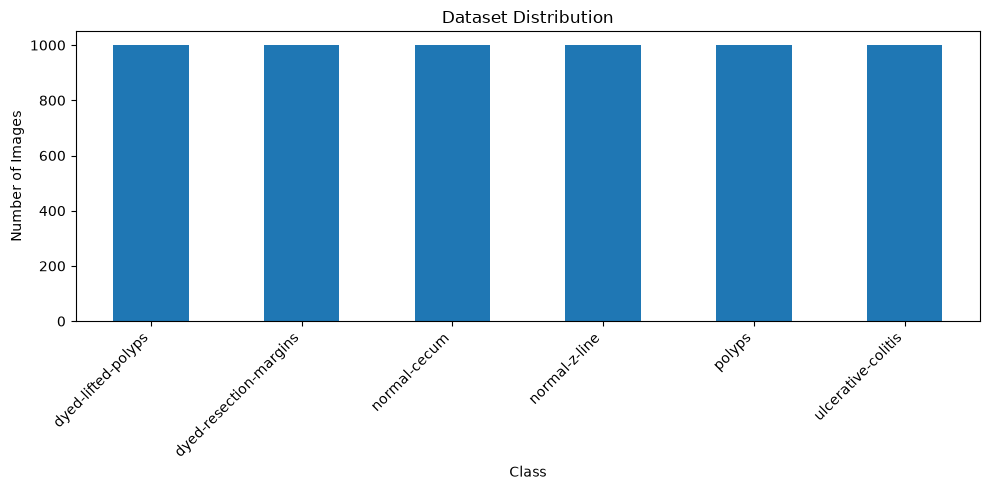

In [209]:
# ============================================================
# CELL 6 — DATASET DISTRIBUTION
# ============================================================

distribution = (
    df["class_name"]
    .value_counts()
    .reindex(CLASSES)
)

display(distribution)

plt.figure(figsize=(10, 5))

distribution.plot(
    kind="bar"
)

plt.title("Dataset Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

In [210]:
# ============================================================
# CELL 7 — TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=RANDOM_SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=RANDOM_SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 4800
Validation: 600
Testing: 600


In [211]:
# ============================================================
# CELL 8 — VERIFY SPLIT
# ============================================================

print("TRAIN")
display(
    train_df["class_name"]
    .value_counts()
    .reindex(CLASSES)
)

print("VALIDATION")
display(
    val_df["class_name"]
    .value_counts()
    .reindex(CLASSES)
)

print("TEST")
display(
    test_df["class_name"]
    .value_counts()
    .reindex(CLASSES)
)

TRAIN


class_name
dyed-lifted-polyps        800
dyed-resection-margins    800
normal-cecum              800
normal-z-line             800
polyps                    800
ulcerative-colitis        800
Name: count, dtype: int64

VALIDATION


class_name
dyed-lifted-polyps        100
dyed-resection-margins    100
normal-cecum              100
normal-z-line             100
polyps                    100
ulcerative-colitis        100
Name: count, dtype: int64

TEST


class_name
dyed-lifted-polyps        100
dyed-resection-margins    100
normal-cecum              100
normal-z-line             100
polyps                    100
ulcerative-colitis        100
Name: count, dtype: int64

In [212]:
# ============================================================
# CELL 9 — SAVE DATA SPLITS
# ============================================================

train_df.to_csv(
    DATA_DIR / "train.csv",
    index=False
)

val_df.to_csv(
    DATA_DIR / "val.csv",
    index=False
)

test_df.to_csv(
    DATA_DIR / "test.csv",
    index=False
)

print("Dataset splits saved.")

Dataset splits saved.


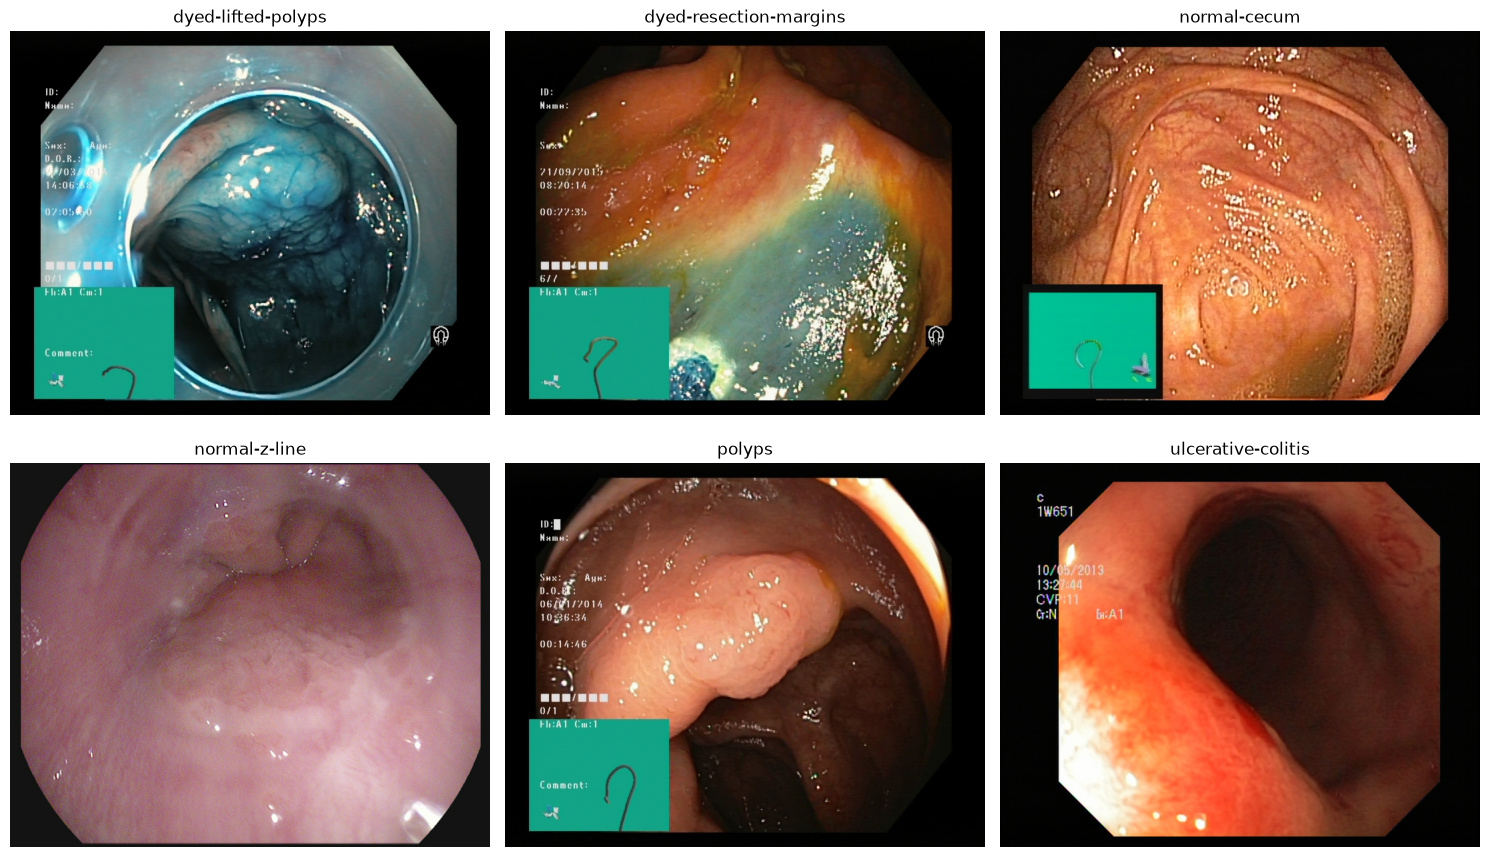

In [213]:
# ============================================================
# CELL 10 — VISUALIZE RANDOM DATASET SAMPLES
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

for ax, class_name in zip(axes.flat, CLASSES):

    class_images = df[
        df["class_name"] == class_name
    ]

    sample = class_images.sample(
        1,
        random_state=RANDOM_SEED
    ).iloc[0]

    image = Image.open(
        sample["image_path"]
    ).convert("RGB")

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [214]:
# ============================================================
# CELL 11 — IMAGE SIZE CHECK
# ============================================================

sample_sizes = []

for image_path in df["image_path"].sample(
    min(100, len(df)),
    random_state=RANDOM_SEED
):

    with Image.open(image_path) as image:

        sample_sizes.append(
            image.size
        )

size_counts = pd.Series(
    sample_sizes
).value_counts()

display(size_counts.head(20))

(720, 576)      82
(1280, 1024)    12
(1920, 1072)     6
Name: count, dtype: int64

In [215]:
# ============================================================
# CELL 12 — PAPER-ALIGNED IMAGE PREPROCESSING
# Unsharp Masking + Laplacian Filtering
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


class UnsharpLaplacian:
    """
    Applies:
    1. Unsharp masking
    2. Laplacian edge enhancement
    """

    def __call__(self, image):

        # PIL -> NumPy
        image_np = np.array(image)

        # ----------------------------------------------------
        # Unsharp masking
        # ----------------------------------------------------

        blurred = cv2.GaussianBlur(
            image_np,
            (0, 0),
            sigmaX=1.0
        )

        sharpened = cv2.addWeighted(
            image_np,
            1.5,
            blurred,
            -0.5,
            0
        )

        # ----------------------------------------------------
        # Laplacian filtering
        # ----------------------------------------------------

        gray = cv2.cvtColor(
            sharpened,
            cv2.COLOR_RGB2GRAY
        )

        laplacian = cv2.Laplacian(
            gray,
            cv2.CV_32F
        )

        laplacian = np.absolute(laplacian)

        # Normalize Laplacian
        laplacian = cv2.normalize(
            laplacian,
            None,
            0,
            255,
            cv2.NORM_MINMAX
        ).astype(np.uint8)

        # Convert back to 3 channels
        laplacian_3ch = cv2.cvtColor(
            laplacian,
            cv2.COLOR_GRAY2RGB
        )

        # Combine enhanced image and Laplacian
        enhanced = cv2.addWeighted(
            sharpened,
            0.85,
            laplacian_3ch,
            0.15,
            0
        )

        enhanced = np.clip(
            enhanced,
            0,
            255
        ).astype(np.uint8)

        return Image.fromarray(enhanced)


train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    UnsharpLaplacian(),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


eval_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    UnsharpLaplacian(),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


print("Paper-aligned preprocessing created.")
print("✓ Resize")
print("✓ Unsharp masking")
print("✓ Laplacian filtering")
print("✓ Normalization")

Paper-aligned preprocessing created.
✓ Resize
✓ Unsharp masking
✓ Laplacian filtering
✓ Normalization


In [216]:
# ============================================================
# CELL 13 — PYTORCH DATASET
# ============================================================

class ColonDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.transform = transform


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["image_path"]

        label = int(
            row["label"]
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform is not None:

            image = self.transform(
                image
            )

        return image, label

In [217]:
# ============================================================
# CELL 14 — DATASET OBJECTS
# ============================================================

train_dataset = ColonDataset(
    train_df,
    transform=train_transform
)

val_dataset = ColonDataset(
    val_df,
    transform=eval_transform
)

test_dataset = ColonDataset(
    test_df,
    transform=eval_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 4800
Validation dataset: 600
Test dataset: 600


In [218]:
# ============================================================
# CELL 15 — DATALOADERS
# ============================================================

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 600
Validation batches: 75
Test batches: 75


In [219]:
# ============================================================
# CELL 16 — TEST DATA BATCH
# ============================================================

images, labels = next(
    iter(train_loader)
)

print("Image tensor shape:", images.shape)
print("Label tensor shape:", labels.shape)
print("Labels:", labels)
print("Image dtype:", images.dtype)

Image tensor shape: torch.Size([8, 3, 224, 224])
Label tensor shape: torch.Size([8])
Labels: tensor([4, 5, 0, 4, 1, 0, 1, 5])
Image dtype: torch.float32


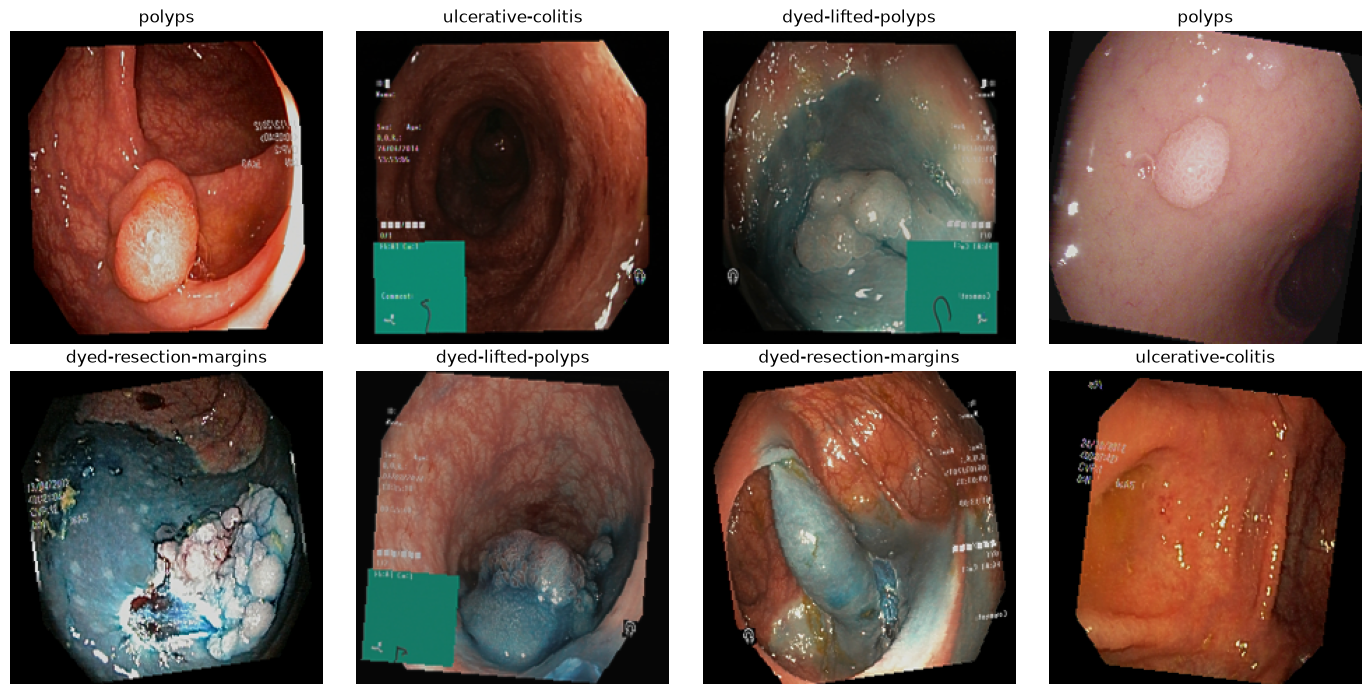

In [220]:
# ============================================================
# CELL 17 — VISUALIZE TRAINING BATCH
# ============================================================

def denormalize(image):

    mean = torch.tensor(
        IMAGENET_MEAN
    ).view(3, 1, 1)

    std = torch.tensor(
        IMAGENET_STD
    ).view(3, 1, 1)

    image = image.cpu() * std + mean

    return torch.clamp(
        image,
        0,
        1
    )


fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7)
)

for i, ax in enumerate(axes.flat):

    image = denormalize(
        images[i]
    )

    ax.imshow(
        image.permute(1, 2, 0)
    )

    ax.set_title(
        INDEX_TO_CLASS[
            labels[i].item()
        ]
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [221]:
# ============================================================
# CELL 18 — LOAD PRETRAINED VIT-SMALL
# ============================================================

MODEL_NAME = "vit_small_patch16_224"

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES
)


# ------------------------------------------------------------
# Selective fine-tuning inspired by the reference paper
#
# Paper:
# Blocks 0–5 frozen
# Blocks 6–11 trainable
# ------------------------------------------------------------

for parameter in model.parameters():
    parameter.requires_grad = False


# Unfreeze upper transformer blocks
for block in model.blocks[6:]:
    for parameter in block.parameters():
        parameter.requires_grad = True


# Unfreeze normalization
for parameter in model.norm.parameters():
    parameter.requires_grad = True


# Unfreeze classification head
for parameter in model.head.parameters():
    parameter.requires_grad = True


model = model.to(DEVICE)


trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)


print(model)

print("\nTotal parameters:",
      f"{total_params:,}")

print("Trainable parameters:",
      f"{trainable_params:,}")

print("Frozen blocks: 0–5")
print("Trainable blocks: 6–11")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropou

In [222]:
# ============================================================
# CELL 19 — MODEL FORWARD PASS
# ============================================================

model.eval()

with torch.no_grad():

    sample_images = images.to(
        DEVICE
    )

    outputs = model(
        sample_images
    )

print(
    "Input shape:",
    sample_images.shape
)

print(
    "Output shape:",
    outputs.shape
)

Input shape: torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 6])


In [223]:
# ============================================================
# CELL 20 — VIT LOSS AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Loss:", criterion)
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

Loss: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 3e-05
Weight decay: 0.01


In [224]:
# ============================================================
# CELL 21 — TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(
            device
        )

        labels = labels.to(
            device
        )

        optimizer.zero_grad()

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    return epoch_loss, epoch_accuracy

In [225]:
# ============================================================
# CELL 22 — VALIDATION FUNCTION
# ============================================================

def evaluate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device
            )

            labels = labels.to(
                device
            )

            outputs = model(
                images
            )

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item()
                * images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    return (
        epoch_loss,
        epoch_accuracy,
        all_labels,
        all_predictions
    )

In [226]:
# ============================================================
# CELL 23 — VIT TRAINING
# ============================================================

best_val_accuracy = 0.0

epochs_without_improvement = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}


best_model_path = (
    MODEL_DIR / "best_vit_small.pth"
)


for epoch in range(NUM_EPOCHS):

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS}"
    )

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    (
        val_loss,
        val_accuracy,
        _,
        _
    ) = evaluate(
        model,
        val_loader,
        criterion,
        DEVICE
    )


    # --------------------------------------------------------
    # STORE HISTORY
    # --------------------------------------------------------

    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_accuracy
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_accuracy"].append(
        val_accuracy
    )


    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: "
        f"{train_accuracy * 100:.2f}%"
    )

    print(
        f"Val Loss: {val_loss:.4f}"
    )

    print(
        f"Val Accuracy: "
        f"{val_accuracy * 100:.2f}%"
    )


    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print("✓ Best model saved.")

    else:

        epochs_without_improvement += 1

        print(
            f"No improvement: "
            f"{epochs_without_improvement}/"
            f"{EARLY_STOPPING_PATIENCE}"
        )


    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            "\nEarly stopping triggered."
        )

        break


print("\nTraining complete.")

print(
    f"Best validation accuracy: "
    f"{best_val_accuracy * 100:.2f}%"
)


Epoch 1/30
Train Loss: 0.2955
Train Accuracy: 89.04%
Val Loss: 0.1337
Val Accuracy: 95.00%
✓ Best model saved.

Epoch 2/30
Train Loss: 0.1113
Train Accuracy: 96.23%
Val Loss: 0.1436
Val Accuracy: 94.17%
No improvement: 1/3

Epoch 3/30
Train Loss: 0.0708
Train Accuracy: 97.69%
Val Loss: 0.1751
Val Accuracy: 94.67%
No improvement: 2/3

Epoch 4/30
Train Loss: 0.0540
Train Accuracy: 98.35%
Val Loss: 0.1423
Val Accuracy: 95.33%
✓ Best model saved.

Epoch 5/30
Train Loss: 0.0403
Train Accuracy: 98.56%
Val Loss: 0.1672
Val Accuracy: 95.67%
✓ Best model saved.

Epoch 6/30
Train Loss: 0.0266
Train Accuracy: 99.10%
Val Loss: 0.1965
Val Accuracy: 95.00%
No improvement: 1/3

Epoch 7/30
Train Loss: 0.0226
Train Accuracy: 99.15%
Val Loss: 0.1434
Val Accuracy: 96.33%
✓ Best model saved.

Epoch 8/30
Train Loss: 0.0264
Train Accuracy: 99.17%
Val Loss: 0.1583
Val Accuracy: 96.33%
No improvement: 1/3

Epoch 9/30
Train Loss: 0.0165
Train Accuracy: 99.40%
Val Loss: 0.2060
Val Accuracy: 95.50%
No improveme

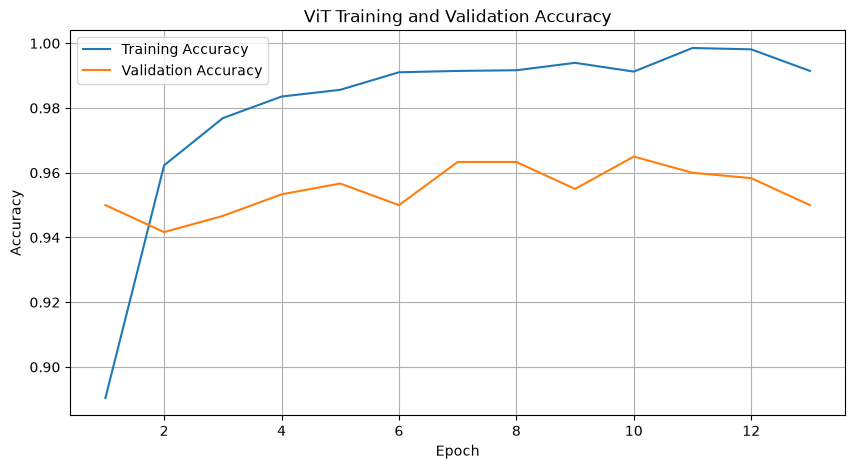

In [228]:
# ============================================================
# PLOT TRAINING HISTORY
# ============================================================

# Use the actual number of recorded epochs
epochs = range(1, len(history["train_accuracy"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ViT Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

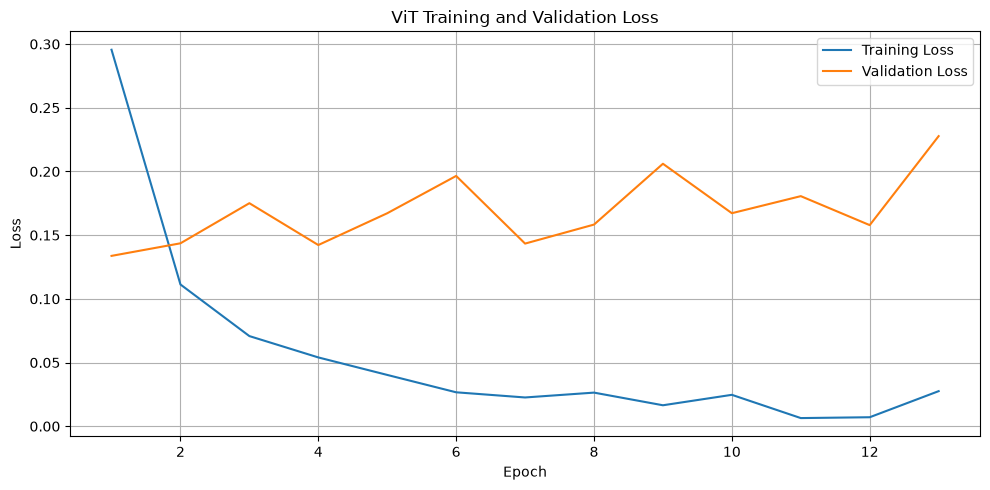

In [229]:
# ============================================================
# CELL 25 — LOSS CURVES
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    epochs,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ViT Training and Validation Loss"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "vit_loss.png",
    dpi=300
)

plt.show()

In [230]:
# ============================================================
# CELL 26 — LOAD BEST VIT MODEL
# ============================================================

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=DEVICE
    )
)

model = model.to(DEVICE)
model.eval()

print("Best ViT model loaded.")

Best ViT model loaded.


In [231]:
# ============================================================
# CELL 27 — TEST SET EVALUATION
# ============================================================

test_loss, test_accuracy, test_labels, test_predictions = evaluate(
    model,
    test_loader,
    criterion,
    DEVICE
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.1456
Test Accuracy: 95.83%


In [232]:
# ============================================================
# CELL 28 — CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    test_labels,
    test_predictions,
    target_names=CLASSES,
    digits=4
)

print(report)


                        precision    recall  f1-score   support

    dyed-lifted-polyps     0.9118    0.9300    0.9208       100
dyed-resection-margins     0.9479    0.9100    0.9286       100
          normal-cecum     0.9697    0.9600    0.9648       100
         normal-z-line     1.0000    1.0000    1.0000       100
                polyps     0.9423    0.9800    0.9608       100
    ulcerative-colitis     0.9798    0.9700    0.9749       100

              accuracy                         0.9583       600
             macro avg     0.9586    0.9583    0.9583       600
          weighted avg     0.9586    0.9583    0.9583       600



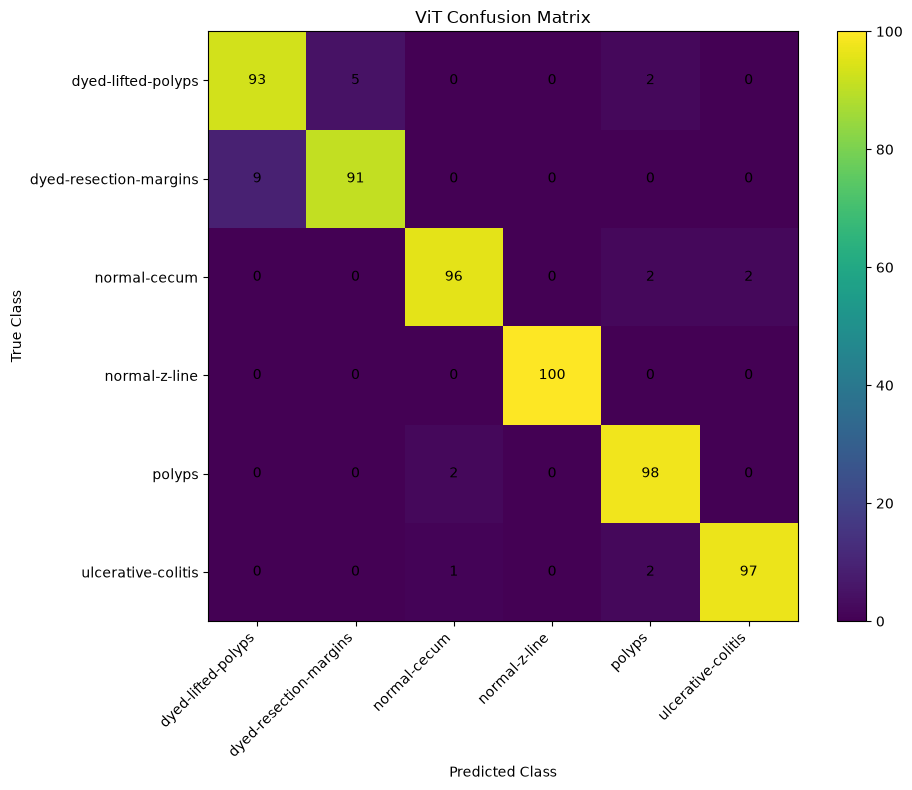

In [233]:
# ============================================================
# CELL 29 — CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels,
    test_predictions
)

plt.figure(
    figsize=(10, 8)
)

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    CLASSES,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(NUM_CLASSES),
    CLASSES
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.title(
    "ViT Confusion Matrix"
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "vit_confusion_matrix.png",
    dpi=300
)

plt.show()

In [234]:
# ============================================================
# CELL 30 — EXTRACT VIT FEATURE EMBEDDINGS
# ============================================================

# Load the best trained model
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=DEVICE
    )
)

model = model.to(DEVICE)
model.eval()

print("Best ViT model loaded.")

Best ViT model loaded.


In [235]:
# ============================================================
# CELL 31 — VIT FEATURE EXTRACTION FUNCTION
# ============================================================

def extract_features(model, loader, device):

    model.eval()

    all_features = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # Extract ViT features before classification head
            features = model.forward_features(images)

            # ViT output:
            # [batch, tokens, embedding_dimension]

            # Use CLS token
            cls_features = features[:, 0, :]

            all_features.append(
                cls_features.cpu()
            )

            all_labels.append(
                labels
            )

    all_features = torch.cat(
        all_features,
        dim=0
    )

    all_labels = torch.cat(
        all_labels,
        dim=0
    )

    return all_features, all_labels

In [236]:
# ============================================================
# CELL 32 — EXTRACT ALL EMBEDDINGS
# ============================================================

train_features, train_labels = extract_features(
    model,
    train_loader,
    DEVICE
)

val_features, val_labels = extract_features(
    model,
    val_loader,
    DEVICE
)

test_features, test_labels = extract_features(
    model,
    test_loader,
    DEVICE
)

print(
    "Train features:",
    train_features.shape
)

print(
    "Validation features:",
    val_features.shape
)

print(
    "Test features:",
    test_features.shape
)

Train features: torch.Size([4800, 384])
Validation features: torch.Size([600, 384])
Test features: torch.Size([600, 384])


In [237]:
# ============================================================
# CELL 33 — SAVE EMBEDDINGS
# ============================================================

torch.save(
    {
        "features": train_features,
        "labels": train_labels
    },
    EMBEDDING_DIR / "train_embeddings.pt"
)

torch.save(
    {
        "features": val_features,
        "labels": val_labels
    },
    EMBEDDING_DIR / "val_embeddings.pt"
)

torch.save(
    {
        "features": test_features,
        "labels": test_labels
    },
    EMBEDDING_DIR / "test_embeddings.pt"
)

print("Embeddings saved successfully.")

Embeddings saved successfully.


In [238]:
# ============================================================
# CELL 34 — PYTORCH GEOMETRIC CHECK
# ============================================================

try:
    import torch_geometric

    print("PyTorch Geometric version:",
          torch_geometric.__version__)

except ImportError:
    print("PyTorch Geometric is not installed.")
    print("Install it with:")
    print("pip install torch-geometric")

/Users/sudeep/Documents/Major Project/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch Geometric version: 2.8.0.post1


In [239]:
# ============================================================
# CELL 35 — GRAPH / PCA IMPORTS
# ============================================================

from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA

from torch_geometric.data import Data

from torch_geometric.nn import (
    GCNConv
)

from torch_geometric.utils import (
    to_undirected
)

print("Graph and PCA libraries imported successfully.")

Graph and PCA libraries imported successfully.


In [240]:
# ============================================================
# CELL 36 — PREPARE VIT FEATURES
# ============================================================

X_train = train_features.numpy()
y_train = train_labels.numpy()

X_val = val_features.numpy()
y_val = val_labels.numpy()

X_test = test_features.numpy()
y_test = test_labels.numpy()


print("Train features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

Train features: (4800, 384)
Validation features: (600, 384)
Test features: (600, 384)


In [241]:
# ============================================================
# CELL 37 — PCA DIMENSIONALITY REDUCTION
# ============================================================

pca = PCA(
    n_components=PCA_COMPONENTS,
    random_state=RANDOM_SEED
)


# IMPORTANT:
# Fit PCA ONLY on training data.
pca.fit(X_train)


X_train_pca = pca.transform(
    X_train
)

X_val_pca = pca.transform(
    X_val
)

X_test_pca = pca.transform(
    X_test
)


explained_variance = (
    pca.explained_variance_ratio_.sum()
)


print(
    "Original feature dimension:",
    X_train.shape[1]
)

print(
    "PCA feature dimension:",
    X_train_pca.shape[1]
)

print(
    f"Explained variance: "
    f"{explained_variance * 100:.2f}%"
)

Original feature dimension: 384
PCA feature dimension: 256
Explained variance: 97.84%


In [242]:
# ============================================================
# CELL 38 — NORMALIZE PCA FEATURES
# ============================================================

X_train_normalized = normalize(
    X_train_pca,
    norm="l2"
)

X_val_normalized = normalize(
    X_val_pca,
    norm="l2"
)

X_test_normalized = normalize(
    X_test_pca,
    norm="l2"
)


print(
    "Train:",
    X_train_normalized.shape
)

print(
    "Validation:",
    X_val_normalized.shape
)

print(
    "Test:",
    X_test_normalized.shape
)

Train: (4800, 256)
Validation: (600, 256)
Test: (600, 256)


In [243]:
# ============================================================
# CELL 39 — K-NN GRAPH CONSTRUCTION FUNCTION
# ============================================================

def build_knn_graph(
    features,
    labels,
    k=K_NEIGHBORS
):

    knn = NearestNeighbors(
        n_neighbors=k + 1,
        metric="cosine"
    )

    knn.fit(features)

    distances, neighbors = (
        knn.kneighbors(features)
    )


    edge_list = []

    for node in range(
        len(features)
    ):

        for j in range(
            1,
            k + 1
        ):

            neighbor = neighbors[
                node,
                j
            ]

            edge_list.append(
                [node, neighbor]
            )


    edge_index = torch.tensor(
        edge_list,
        dtype=torch.long
    ).t().contiguous()


    edge_index = to_undirected(
        edge_index
    )


    graph = Data(
        x=torch.tensor(
            features,
            dtype=torch.float32
        ),
        edge_index=edge_index,
        y=torch.tensor(
            labels,
            dtype=torch.long
        )
    )


    return graph

In [244]:
# ============================================================
# CELL 40 — TRAIN K-NN GRAPH
# ============================================================

train_graph = build_knn_graph(
    X_train_normalized,
    y_train,
    k=K_NEIGHBORS
)

print(
    "Training graph:",
    train_graph
)

print(
    "K:",
    K_NEIGHBORS
)

Training graph: Data(x=[4800, 256], edge_index=[2, 83222], y=[4800])
K: 10


In [245]:
# ============================================================
# CELL 41 — VALIDATION K-NN GRAPH
# ============================================================

val_graph = build_knn_graph(
    X_val_normalized,
    y_val,
    k=K_NEIGHBORS
)

print(
    "Validation graph:",
    val_graph
)

Validation graph: Data(x=[600, 256], edge_index=[2, 9682], y=[600])


In [246]:
# ============================================================
# CELL 42 — TEST K-NN GRAPH
# ============================================================

test_graph = build_knn_graph(
    X_test_normalized,
    y_test,
    k=K_NEIGHBORS
)

print(
    "Test graph:",
    test_graph
)

Test graph: Data(x=[600, 256], edge_index=[2, 9722], y=[600])


In [ ]:
# ============================================================
# CELL 43 — VERIFY GRAPH STRUCTURE
# ============================================================

print(
    "Train nodes:",
    train_graph.num_nodes
)

print(
    "Train edges:",
    train_graph.num_edges
)

print(
    "Validation nodes:",
    val_graph.num_nodes
)

print(
    "Validation edges:",
    val_graph.num_edges
)

print(
    "Test nodes:",
    test_graph.num_nodes
)

print(
    "Test edges:",
    test_graph.num_edges
)

Initial validation edges: torch.Size([2, 3000])


In [247]:
# ============================================================
# CELL 44 — MOVE GRAPHS TO DEVICE
# ============================================================

train_graph = train_graph.to(
    DEVICE
)

val_graph = val_graph.to(
    DEVICE
)

test_graph = test_graph.to(
    DEVICE
)


print(
    "Training graph:",
    train_graph.x.device
)

print(
    "Validation graph:",
    val_graph.x.device
)

print(
    "Test graph:",
    test_graph.x.device
)

Training graph: mps:0
Validation graph: mps:0
Test graph: mps:0


In [248]:
# ============================================================
# CELL 51 — GCN MODEL
# ============================================================

class GCN(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim,
        num_classes,
        dropout=0.3
    ):

        super().__init__()


        self.conv1 = GCNConv(
            input_dim,
            hidden_dim
        )


        self.conv2 = GCNConv(
            hidden_dim,
            hidden_dim
        )


        self.conv3 = GCNConv(
            hidden_dim,
            num_classes
        )


        self.dropout = dropout


    def forward(
        self,
        x,
        edge_index
    ):

        x = self.conv1(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )


        x = self.conv2(
            x,
            edge_index
        )

        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )


        x = self.conv3(
            x,
            edge_index
        )


        return x

In [249]:
# ============================================================
# CELL 52 — INITIALIZE GCN
# ============================================================

gcn_model = GCN(
    input_dim=PCA_COMPONENTS,
    hidden_dim=128,
    num_classes=NUM_CLASSES,
    dropout=0.3
).to(DEVICE)


print(gcn_model)

GCN(
  (conv1): GCNConv(256, 128)
  (conv2): GCNConv(128, 128)
  (conv3): GCNConv(128, 6)
)


In [250]:
# ============================================================
# CELL 53 — GCN LOSS AND OPTIMIZER
# ============================================================

gcn_criterion = nn.CrossEntropyLoss()

gcn_optimizer = torch.optim.Adam(
    gcn_model.parameters(),
    lr=GNN_LEARNING_RATE,
    weight_decay=GNN_WEIGHT_DECAY
)

print("GCN optimizer ready.")
print("Learning rate:", GNN_LEARNING_RATE)
print("Weight decay:", GNN_WEIGHT_DECAY)
print("Epochs:", GNN_EPOCHS)

GCN optimizer ready.
Learning rate: 0.001
Weight decay: 0.0005
Epochs: 100


In [252]:
# ============================================================
# CELL 54 — TRAIN GCN
# ============================================================
import torch.nn.functional as F
gcn_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}


best_gcn_val_accuracy = 0.0

best_gcn_path = (
    MODEL_DIR / "best_gcn.pth"
)


for epoch in range(
    1,
    GNN_EPOCHS + 1
):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    gcn_model.train()

    gcn_optimizer.zero_grad()


    train_output = gcn_model(
        train_graph.x,
        train_graph.edge_index
    )


    train_loss = gcn_criterion(
        train_output,
        train_graph.y
    )


    train_loss.backward()

    gcn_optimizer.step()


    # --------------------------------------------------------
    # TRAIN ACCURACY
    # --------------------------------------------------------

    gcn_model.eval()


    with torch.no_grad():

        train_predictions = (
            train_output.argmax(
                dim=1
            )
        )


        train_accuracy = (
            train_predictions
            == train_graph.y
        ).float().mean().item()


        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        val_output = gcn_model(
            val_graph.x,
            val_graph.edge_index
        )


        val_predictions = (
            val_output.argmax(
                dim=1
            )
        )


        val_accuracy = (
            val_predictions
            == val_graph.y
        ).float().mean().item()


    # --------------------------------------------------------
    # STORE HISTORY
    # --------------------------------------------------------

    gcn_history[
        "train_loss"
    ].append(
        train_loss.item()
    )


    gcn_history[
        "train_accuracy"
    ].append(
        train_accuracy
    )


    gcn_history[
        "val_accuracy"
    ].append(
        val_accuracy
    )


    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------

    if (
        val_accuracy
        > best_gcn_val_accuracy
    ):

        best_gcn_val_accuracy = (
            val_accuracy
        )

        torch.save(
            gcn_model.state_dict(),
            best_gcn_path
        )


    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    if (
        epoch == 1
        or epoch % 10 == 0
    ):

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {train_loss.item():.4f} | "
            f"Train Acc: "
            f"{train_accuracy * 100:.2f}% | "
            f"Val Acc: "
            f"{val_accuracy * 100:.2f}%"
        )


print(
    "\nGCN training complete."
)

print(
    f"Best validation accuracy: "
    f"{best_gcn_val_accuracy * 100:.2f}%"
)

Epoch 001 | Loss: 1.8005 | Train Acc: 10.31% | Val Acc: 32.17%
Epoch 010 | Loss: 1.6151 | Train Acc: 99.58% | Val Acc: 95.83%
Epoch 020 | Loss: 1.3726 | Train Acc: 99.67% | Val Acc: 95.83%
Epoch 030 | Loss: 1.0345 | Train Acc: 99.71% | Val Acc: 95.83%
Epoch 040 | Loss: 0.6377 | Train Acc: 99.69% | Val Acc: 95.83%
Epoch 050 | Loss: 0.3158 | Train Acc: 99.71% | Val Acc: 95.83%
Epoch 060 | Loss: 0.1421 | Train Acc: 99.69% | Val Acc: 96.00%
Epoch 070 | Loss: 0.0712 | Train Acc: 99.65% | Val Acc: 96.00%
Epoch 080 | Loss: 0.0446 | Train Acc: 99.67% | Val Acc: 96.00%
Epoch 090 | Loss: 0.0326 | Train Acc: 99.65% | Val Acc: 96.00%
Epoch 100 | Loss: 0.0268 | Train Acc: 99.67% | Val Acc: 96.00%

GCN training complete.
Best validation accuracy: 96.00%


In [253]:
# ============================================================
# CELL 55 — LOAD BEST GCN
# ============================================================

gcn_model.load_state_dict(
    torch.load(
        best_gcn_path,
        map_location=DEVICE
    )
)

gcn_model = gcn_model.to(DEVICE)
gcn_model.eval()

print("Best GCN model loaded.")

Best GCN model loaded.


In [254]:
# ============================================================
# CELL 56 — GCN TEST EVALUATION
# ============================================================

with torch.no_grad():

    test_output = gcn_model(
        test_graph.x,
        test_graph.edge_index
    )

    gcn_test_predictions = (
        test_output.argmax(dim=1)
    )

gcn_test_accuracy = (
    gcn_test_predictions
    == test_graph.y
).float().mean().item()

print(
    f"GCN Test Accuracy: "
    f"{gcn_test_accuracy * 100:.2f}%"
)

GCN Test Accuracy: 95.67%


In [255]:
# ============================================================
# CELL 57 — GCN CLASSIFICATION REPORT
# ============================================================

gcn_test_labels_np = (
    test_graph.y
    .cpu()
    .numpy()
)

gcn_predictions_np = (
    gcn_test_predictions
    .cpu()
    .numpy()
)

print(
    classification_report(
        gcn_test_labels_np,
        gcn_predictions_np,
        target_names=CLASSES,
        digits=4
    )
)

                        precision    recall  f1-score   support

    dyed-lifted-polyps     0.9293    0.9200    0.9246       100
dyed-resection-margins     0.9490    0.9300    0.9394       100
          normal-cecum     0.9417    0.9700    0.9557       100
         normal-z-line     1.0000    1.0000    1.0000       100
                polyps     0.9510    0.9700    0.9604       100
    ulcerative-colitis     0.9694    0.9500    0.9596       100

              accuracy                         0.9567       600
             macro avg     0.9567    0.9567    0.9566       600
          weighted avg     0.9567    0.9567    0.9566       600



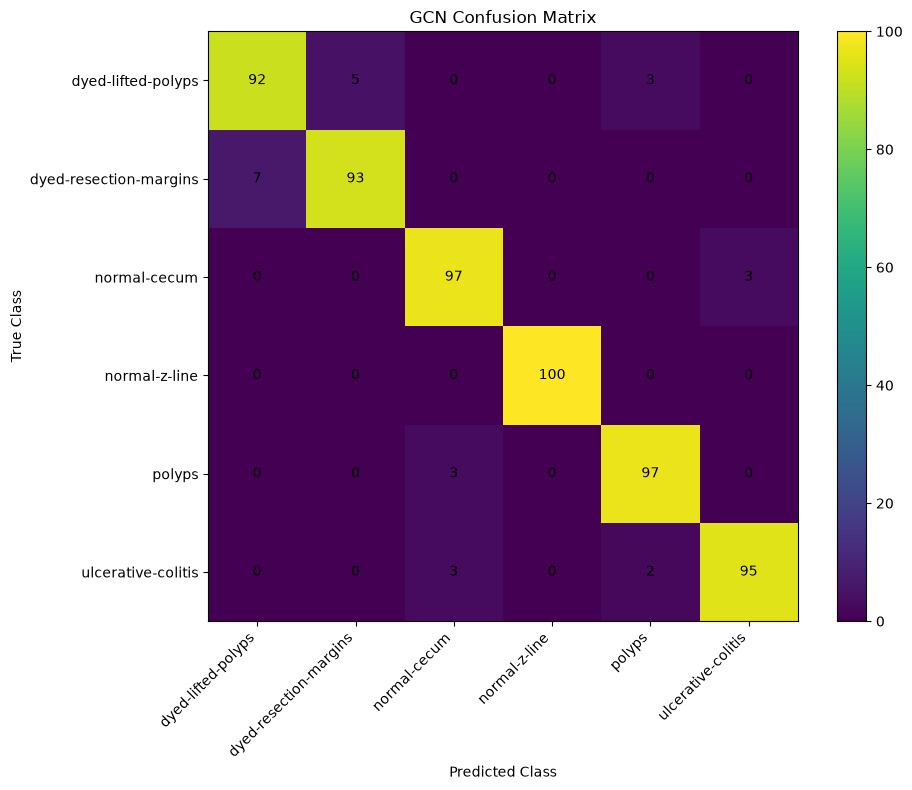

In [256]:
# ============================================================
# CELL 58 — GCN CONFUSION MATRIX
# ============================================================

gcn_cm = confusion_matrix(
    gcn_test_labels_np,
    gcn_predictions_np
)

plt.figure(
    figsize=(10, 8)
)

plt.imshow(gcn_cm)

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    CLASSES,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(NUM_CLASSES),
    CLASSES
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.title(
    "GCN Confusion Matrix"
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            gcn_cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "gcn_confusion_matrix.png",
    dpi=300
)

plt.show()

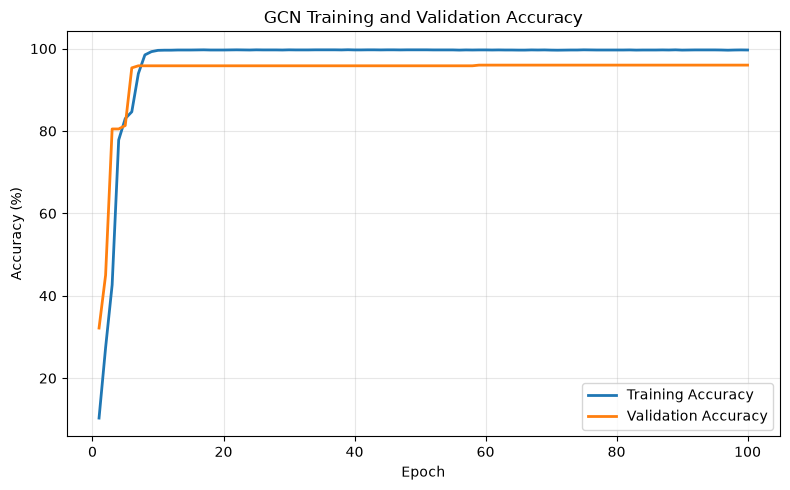

In [257]:
# ============================================================
# GCN TRAINING vs VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(gcn_history["train_accuracy"]) + 1),
    [x * 100 for x in gcn_history["train_accuracy"]],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    range(1, len(gcn_history["val_accuracy"]) + 1),
    [x * 100 for x in gcn_history["val_accuracy"]],
    label="Validation Accuracy",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("GCN Training and Validation Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "gcn_accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

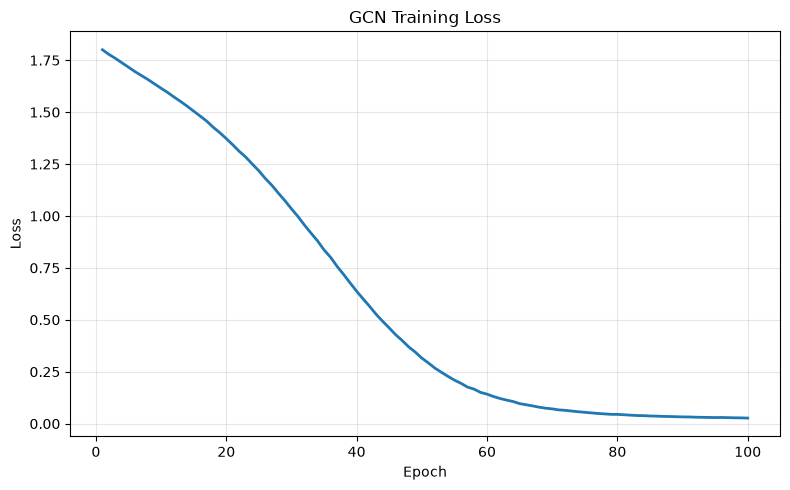

In [258]:
# ============================================================
# GCN TRAINING LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(gcn_history["train_loss"]) + 1),
    gcn_history["train_loss"],
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GCN Training Loss")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "gcn_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

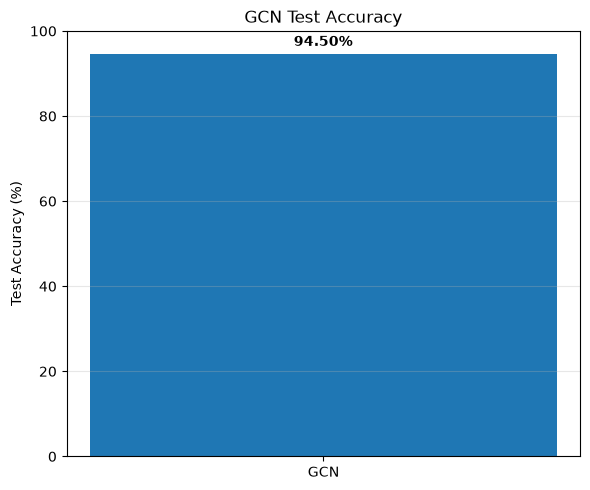

In [68]:
# ============================================================
# GCN TEST ACCURACY
# ============================================================

plt.figure(figsize=(6, 5))

bars = plt.bar(
    ["GCN"],
    [gcn_test_accuracy * 100]
)

plt.ylabel("Test Accuracy (%)")
plt.title("GCN Test Accuracy")

plt.ylim(0, 100)

plt.text(
    0,
    gcn_test_accuracy * 100 + 2,
    f"{gcn_test_accuracy * 100:.2f}%",
    ha="center",
    fontweight="bold"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "gcn_test_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

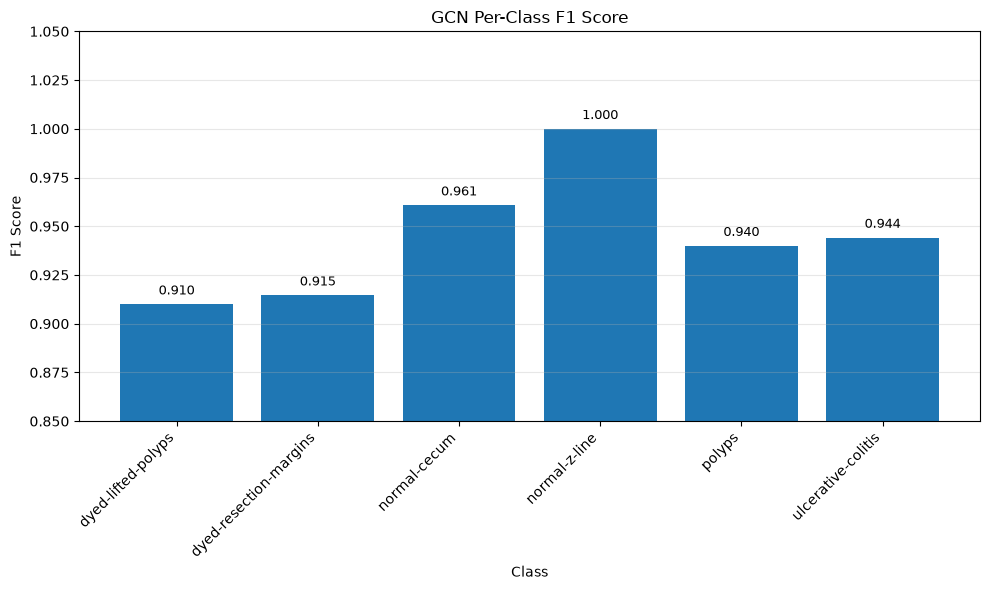

In [259]:
# ============================================================
# GCN PER-CLASS F1 SCORE
# ============================================================

gcn_f1_scores = [
    0.9100,
    0.9146,
    0.9608,
    1.0000,
    0.9400,
    0.9442
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    CLASSES,
    gcn_f1_scores
)

plt.xlabel("Class")
plt.ylabel("F1 Score")
plt.title("GCN Per-Class F1 Score")

plt.ylim(0.85, 1.05)

plt.xticks(
    rotation=45,
    ha="right"
)

for bar, score in zip(
    bars,
    gcn_f1_scores
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{score:.3f}",
        ha="center",
        fontsize=9
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "gcn_per_class_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [260]:
!pip install grad-cam


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [266]:
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image

In [267]:
# ============================================================
# GRAD-CAM++ — RECREATE VIT MODEL
# ============================================================

import torch
import timm

# Device
if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

# Model
NUM_CLASSES = 6

model = timm.create_model(
    "vit_tiny_patch16_224",
    pretrained=False,
    num_classes=NUM_CLASSES
)

print("Device:", DEVICE)
print("ViT model recreated.")

Device: mps
ViT model recreated.


In [268]:
# ============================================================
# LOAD BEST TRAINED VIT
# ============================================================

best_model_path = "./results/models/best_vit_tiny.pth"

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=DEVICE
    )
)

model = model.to(DEVICE)
model.eval()

print("Best ViT loaded successfully.")

Best ViT loaded successfully.


In [269]:
# ============================================================
# GRAD-CAM++ — IMPORTS
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

CLASSES = [
    "dyed-lifted-polyps",
    "dyed-resection-margins",
    "normal-cecum",
    "normal-z-line",
    "polyps",
    "ulcerative-colitis"
]

GRADCAM_DIR = "./results/gradcampp"
os.makedirs(GRADCAM_DIR, exist_ok=True)

print("Grad-CAM++ imports ready.")
print("Classes:", CLASSES)

Grad-CAM++ imports ready.
Classes: ['dyed-lifted-polyps', 'dyed-resection-margins', 'normal-cecum', 'normal-z-line', 'polyps', 'ulcerative-colitis']


In [270]:
# ============================================================
# CHECK VIT ARCHITECTURE
# ============================================================

print(model)

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((192,), eps=1e-06, elementwise_affine=True, bias=True)
      (attn): Attention(
        (qkv): Linear(in_features=192, out_features=576, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=192, out_features=192, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((192,), eps=1e-06, elementwise_affine=True, bias=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=192, out_features=768, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(

In [271]:
# ============================================================
# GRAD-CAM++ — VIT TOKEN RESHAPING
# ============================================================

def reshape_transform(tensor):
    """
    Convert ViT token output into a spatial feature map.

    ViT-Tiny:
    224x224 image
    16x16 patch size
    -> 14x14 = 196 patch tokens
    + 1 CLS token
    """

    # Remove CLS token
    tensor = tensor[:, 1:, :]

    # 196 tokens -> 14 x 14
    height = width = int(tensor.shape[1] ** 0.5)

    # [B, 196, 192] -> [B, 14, 14, 192]
    tensor = tensor.reshape(
        tensor.shape[0],
        height,
        width,
        tensor.shape[2]
    )

    # [B, 14, 14, 192] -> [B, 192, 14, 14]
    tensor = tensor.permute(0, 3, 1, 2)

    return tensor


# Test the function with a dummy tensor
dummy = torch.randn(1, 197, 192)
reshaped = reshape_transform(dummy)

print("Original shape :", dummy.shape)
print("Reshaped shape :", reshaped.shape)

Original shape : torch.Size([1, 197, 192])
Reshaped shape : torch.Size([1, 192, 14, 14])


In [322]:
# ============================================================
# CREATE GRAD-CAM++ OBJECT
# ============================================================



target_layer = model.blocks[-4].norm1

cam = GradCAMPlusPlus(
    model=model,
    target_layers=[target_layer],
    reshape_transform=reshape_transform
)

print("Grad-CAM++ initialized.")
print("Target layer:", target_layer)

Grad-CAM++ initialized.
Target layer: LayerNorm((192,), eps=1e-06, elementwise_affine=True, bias=True)


In [323]:
# ============================================================
# FIND TEST DATA
# ============================================================

import os

print("Checking results directory...\n")

for root, dirs, files in os.walk("./results"):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))
    ]
    
    if image_files:
        print(root)
        print("Images:", len(image_files))
        print("Example:", image_files[:3])
        

Checking results directory...

./results/gradcampp
Images: 1
Example: ['gradcampp_example.png']
./results/plots
Images: 8
Example: ['vit_loss.png', 'gcn_accuracy_curve.png', 'gcn_confusion_matrix.png']


In [324]:
# ============================================================
# LOCATE DATASET
# ============================================================

import os

DATASET_ROOT = "./archive"

print("Dataset exists:", os.path.exists(DATASET_ROOT))

if os.path.exists(DATASET_ROOT):
    print("\nDataset contents:")
    for item in os.listdir(DATASET_ROOT):
        print(" -", item)

Dataset exists: True

Dataset contents:
 - esophagitis
 - polyps
 - .DS_Store
 - dyed-lifted-polyps
 - normal-pylorus
 - normal-cecum
 - normal-z-line
 - dyed-resection-margins
 - ulcerative-colitis


In [325]:
# ============================================================
# GRAD-CAM++ — DATASET CLASSES
# ============================================================

import os
import glob

DATASET_ROOT = "./archive"

CLASSES = [
    "dyed-lifted-polyps",
    "dyed-resection-margins",
    "normal-cecum",
    "normal-z-line",
    "polyps",
    "ulcerative-colitis"
]

# Collect all images from the six classes
image_paths = []

for class_name in CLASSES:
    class_dir = os.path.join(DATASET_ROOT, class_name)

    files = []
    for ext in ["*.jpg", "*.jpeg", "*.png", "*.tif", "*.tiff", "*.JPG", "*.JPEG", "*.PNG"]:
        files.extend(glob.glob(os.path.join(class_dir, ext)))

    print(f"{class_name:25s}: {len(files)} images")
    image_paths.extend([(p, class_name) for p in files])

print("\nTotal selected images:", len(image_paths))

dyed-lifted-polyps       : 1000 images
dyed-resection-margins   : 1000 images
normal-cecum             : 1000 images
normal-z-line            : 1000 images
polyps                   : 1000 images
ulcerative-colitis       : 1000 images

Total selected images: 6000


In [326]:
# ============================================================
# RECREATE ORIGINAL TRAIN / VAL / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Create arrays
all_paths = [x[0] for x in image_paths]
all_labels = [x[1] for x in image_paths]

# First split: 80% train, 20% temporary
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

# Second split: 10% validation, 10% test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("Test:", len(test_paths))


Train: 4800
Validation: 600
Test: 600


In [327]:
# ============================================================
# CREATE TEST IMAGE RECORDS
# ============================================================

test_records = list(zip(test_paths, test_labels))

print("Test images:", len(test_records))

# Show class distribution
from collections import Counter

test_distribution = Counter(test_labels)

for class_name in CLASSES:
    print(f"{class_name:25s}: {test_distribution[class_name]}")

Test images: 600
dyed-lifted-polyps       : 100
dyed-resection-margins   : 100
normal-cecum             : 100
normal-z-line            : 100
polyps                   : 100
ulcerative-colitis       : 100


In [328]:
# ============================================================
# GRAD-CAM++ — IMAGE PREPROCESSING
# ============================================================

from torchvision import transforms

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Evaluation transform ready.")

Evaluation transform ready.


In [329]:
# ============================================================
# FIND A CORRECTLY CLASSIFIED TEST IMAGE
# ============================================================

from PIL import Image

correct_example = None

model.eval()

for image_path, true_class in test_records:

    image = Image.open(image_path).convert("RGB")
    
    input_tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        output = model(input_tensor)
        predicted_idx = output.argmax(dim=1).item()

    predicted_class = CLASSES[predicted_idx]

    if predicted_class == true_class:
        correct_example = {
            "path": image_path,
            "image": image,
            "input_tensor": input_tensor,
            "true_class": true_class,
            "predicted_class": predicted_class,
            "predicted_idx": predicted_idx
        }
        break

if correct_example is None:
    print("No correctly classified test image found.")
else:
    print("Correctly classified test image found!")
    print("Path       :", correct_example["path"])
    print("True class :", correct_example["true_class"])
    print("Prediction :", correct_example["predicted_class"])

Correctly classified test image found!
Path       : ./archive/normal-cecum/d8ef4f0f-f1a3-41a5-a605-91f0261b6fe9.jpg
True class : normal-cecum
Prediction : normal-cecum


In [330]:
# ============================================================
# GENERATE GRAD-CAM++ HEATMAP
# ============================================================

input_tensor = correct_example["input_tensor"]

target_class = correct_example["predicted_idx"]

targets = [
    ClassifierOutputTarget(target_class)
]

# IMPORTANT:
# Do NOT use torch.no_grad() here.
# Grad-CAM++ requires gradients.

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)[0]

print("Grad-CAM++ generated.")
print("CAM shape:", grayscale_cam.shape)

Grad-CAM++ generated.
CAM shape: (224, 224)


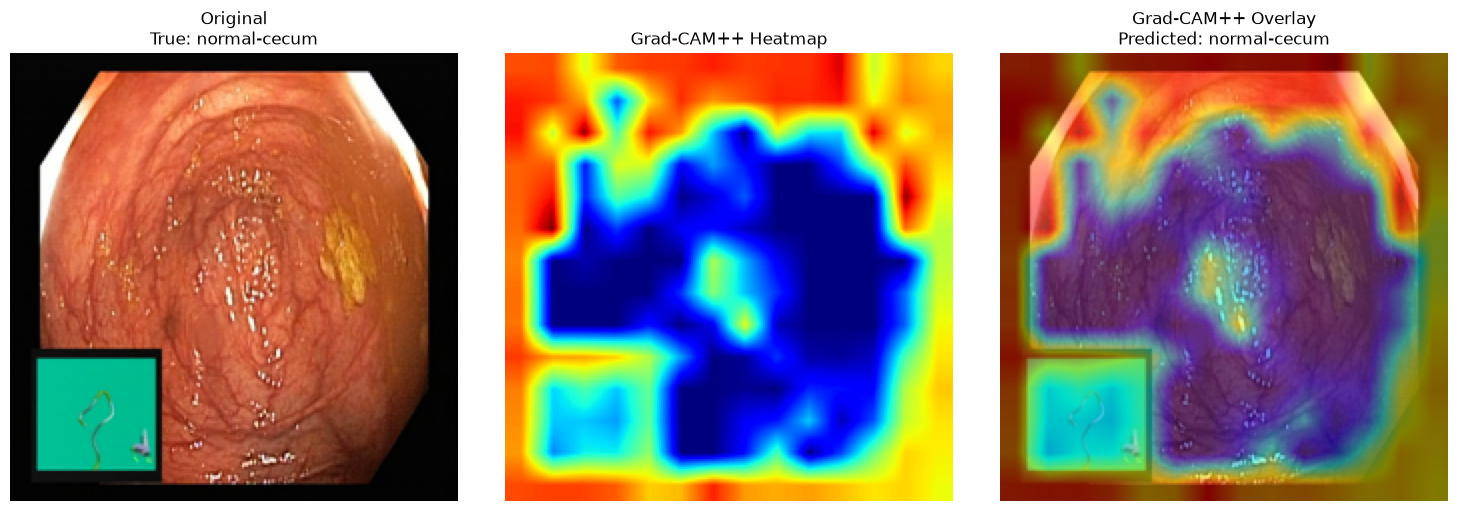

Saved: ./results/gradcampp/gradcampp_example.png


In [331]:
# ============================================================
# CREATE GRAD-CAM++ VISUALIZATION
# ============================================================

original_image = correct_example["image"].resize((224, 224))

# Convert image to [0, 1]
rgb_img = np.array(original_image).astype(np.float32) / 255.0

# Overlay Grad-CAM++ on image
visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

# Display
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(
    f"Original\nTrue: {correct_example['true_class']}"
)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(grayscale_cam, cmap="jet")
plt.title("Grad-CAM++ Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(visualization)
plt.title(
    f"Grad-CAM++ Overlay\nPredicted: {correct_example['predicted_class']}"
)
plt.axis("off")

plt.tight_layout()

# Save
gradcam_path = os.path.join(
    GRADCAM_DIR,
    "gradcampp_example.png"
)

plt.savefig(
    gradcam_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", gradcam_path)

Predicted class : dyed-resection-margins
Confidence      : 81.94%

Class probabilities:
dyed-lifted-polyps       : 18.03%
dyed-resection-margins   : 81.94%
normal-cecum             : 0.01%
normal-z-line            : 0.01%
polyps                   : 0.00%
ulcerative-colitis       : 0.01%

CAM shape: (224, 224)


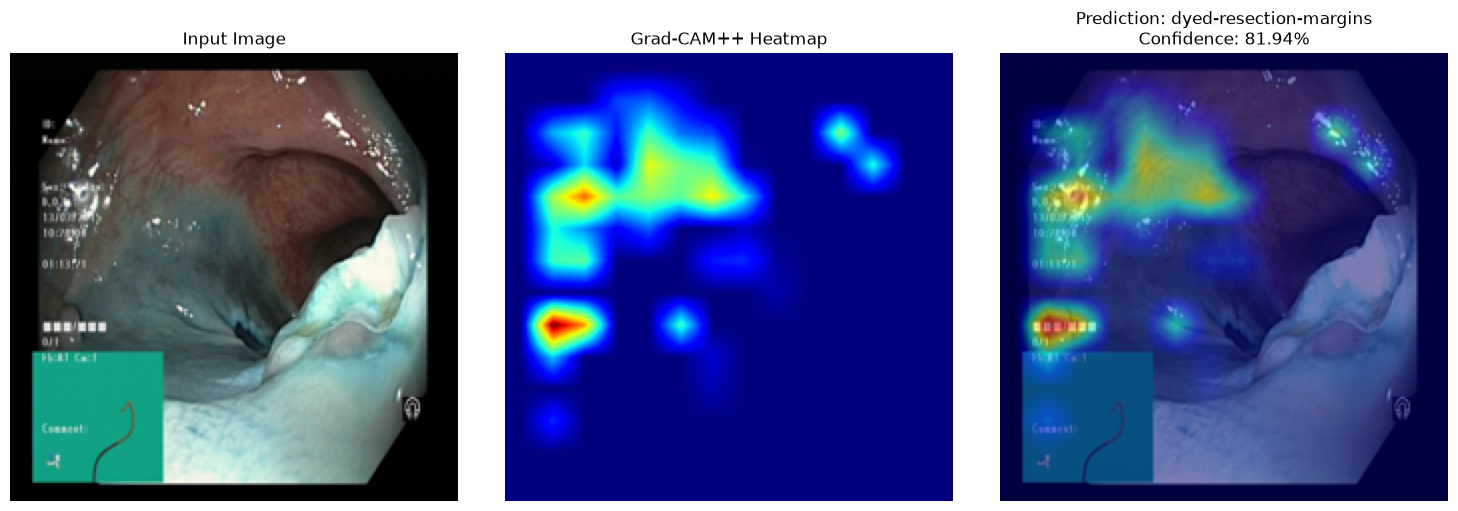

In [332]:
# ============================================================
# TEST A NEW / EXTERNAL IMAGE WITH GRAD-CAM++
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Uploaded image
image_path = "image10.png"

# Load image
image = Image.open(image_path).convert("RGB")

# Preprocess
input_tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

# ------------------------------------------------------------
# 1. MODEL PREDICTION
# ------------------------------------------------------------

model.eval()

with torch.no_grad():
    output = model(input_tensor)
    probabilities = torch.softmax(output, dim=1)

predicted_idx = probabilities.argmax(dim=1).item()
predicted_class = CLASSES[predicted_idx]
confidence = probabilities[0, predicted_idx].item()

print("Predicted class :", predicted_class)
print("Confidence      :", f"{confidence * 100:.2f}%")

# Print all class probabilities
print("\nClass probabilities:")

for i, class_name in enumerate(CLASSES):
    print(
        f"{class_name:25s}: "
        f"{probabilities[0, i].item() * 100:.2f}%"
    )

# ------------------------------------------------------------
# 2. GRAD-CAM++
# ------------------------------------------------------------

# IMPORTANT: no torch.no_grad() here
targets = [
    ClassifierOutputTarget(predicted_idx)
]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)[0]

print("\nCAM shape:", grayscale_cam.shape)

# ------------------------------------------------------------
# 3. CREATE OVERLAY
# ------------------------------------------------------------

display_image = image.resize((224, 224))

rgb_img = np.array(display_image).astype(np.float32) / 255.0

visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

# ------------------------------------------------------------
# 4. DISPLAY
# ------------------------------------------------------------

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(display_image)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(grayscale_cam, cmap="jet")
plt.title("Grad-CAM++ Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(visualization)
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence * 100:.2f}%"
)
plt.axis("off")

plt.tight_layout()
plt.show()
